[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch08-concepts_workbook.ipynb)

# Three words, one unit of weight each

The lecture's words `the cat sat` hold four numbers each, and three learned
matrices turn each word into a query, a key and a value. How does `the`
share its one unit of weight among the three words, and what does it read
from them? What changes once a word may not read the words after it?

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["the", "cat", "sat"]
# The lecture's integer example (claim_8_1 of tools/claim_instances.py): four numbers per word,
# projected to queries, keys and values of width D_K.
X = np.array([[1, 0, 1, 0], [0, 2, 0, 2], [1, 1, 1, 1]])
W_Q = np.array([[1, 0, 1], [1, 0, 0], [0, 0, 1], [0, 1, 1]])
W_K = np.array([[0, 0, 1], [1, 1, 0], [0, 1, 0], [1, 1, 0]])
W_V = np.array([[0, 2, 0], [0, 3, 0], [1, 0, 3], [1, 1, 0]])
Q, K, V, D_K = X @ W_Q, X @ W_K, X @ W_V, 3
# GPT-2 small: 12 blocks of width 768 with 12 heads (Radford et al. 2019).
GPT2_LAYERS, GPT2_WIDTH, GPT2_HEADS = 12, 768, 12
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def numbers(name, x, n, lo, hi):  # a setting typed in a cell: a list of n numbers from lo to hi
    if not (isinstance(x, (list, tuple)) and len(x) == n and all(type(v) in (int, float) and lo <= v <= hi for v in x)):
        raise Refused(f"{name} is {x!r}: {name} takes a list of {n} numbers from {lo} to {hi}.")
    return np.array(x, dtype=float)


def word(name, w):  # one of the three words, typed in a cell
    if w not in WORDS:
        raise Refused(f"{name} is {w!r}: {name} takes one of {', '.join(WORDS)}.")
    return WORDS.index(w)


def bars(title, labels, values, xlabel, colors, fmt="%.3f"):  # one chart of labelled horizontal bars
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=colors)
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.3 * (max(values) or 1)), ylim=(len(values) - 0.5, -0.5))
    plt.show()


def softmax(s):  # one row of scores to weights that sum to 1; a score of -inf gets weight 0
    e = np.exp(np.asarray(s, dtype=float) - max(s))
    return e / e.sum()


# Step 1: the query of one word against the keys of all three.
def scores_of(w):
    i = word("WORD", w)
    print(f"query of {w}: {Q[i]}; keys: " + ", ".join(f"{x} {K[j]}" for j, x in enumerate(WORDS)))
    print(f"scores of {w}: {Q[i] @ K.T}")
    bars(f"scores of {w}", WORDS, Q[i] @ K.T, "query-key dot product", ["C3" if j == i else "C0" for j in range(3)], "%d")


# Step 2: a row of scores, divided by the square root of D_K, to weights and to an output row.
def read(row):
    s = numbers("SCORES", row, 3, -100, 100)
    a = softmax(s / math.sqrt(D_K))
    print(f"scaled scores: {np.round(s / math.sqrt(D_K), 4)}; weights: {np.round(a, 3)}, sum {a.sum():.3f}")
    print(f"output row: weights times the value rows {V.tolist()} = {np.round(a @ V, 3)}")
    bars("weights", WORDS, a, "weight", ["C0"] * 3)


# Step 3: the causal mask before the softmax and the same cells zeroed after it.
def masked(w):
    i = word("WORD", w)
    s = Q[i] @ K.T / math.sqrt(D_K)
    before = softmax(np.where(np.arange(3) <= i, s, -np.inf))
    after = softmax(s) * (np.arange(3) <= i)
    return before, after


def show_mask(w):
    before, after = masked(w)
    for name, a in (("masked before the softmax", before), ("zeroed after the softmax ", after)):
        print(f"{name}: " + ", ".join(f"{v:.4f}" for v in a) + f"; sum {a.sum():.3f}")
    bars(f"weights of {w}", [f"{x}, before" for x in WORDS] + [f"{x}, after" for x in WORDS],
         list(before) + list(after), "weight", ["C2"] * 3 + ["C1"] * 3, "%.4f")


def parameters(width, heads):  # W_Q, W_K, W_V of h heads of width d/h, and W_O of d x d
    return 3 * heads * width * (width // heads) + width * width


display(Markdown(f"`the cat sat`: {len(WORDS)} words, {X.shape[1]} numbers each, queries, keys and values of {D_K}."))

`the cat sat`: 3 words, 4 numbers each, queries, keys and values of 3.

## 1. Queries, keys and scores

The query of a word is its four numbers times `W_Q`, and its key and value
the same numbers times `W_K` and `W_V`. The score of a word for another is
the dot product of its query and the other word's key. Run the cell: which
word scores highest for `the`? Then set `WORD` to `cat` and to `sat`.

query of the: [1 0 2]; keys: the [0 1 1], cat [4 4 0], sat [2 3 1]
scores of the: [2 4 4]


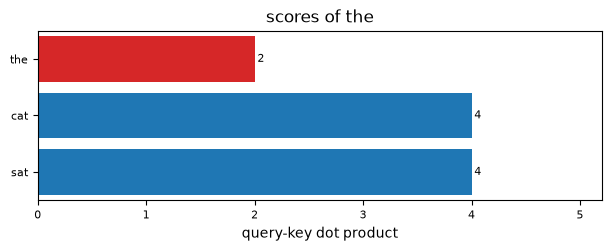

In [2]:
WORD = "the"
scores_of(WORD)

### Solution

In [3]:
rows = "; ".join(f"`{x}` {', '.join(str(v) for v in Q[j] @ K.T)}" for j, x in enumerate(WORDS))
display(Markdown(f"The score rows: {rows}. `the` scores `cat` and `sat` equally and itself lowest; `cat` scores itself "
                 f"highest, {Q[1] @ K[1]}, and `sat` scores `cat` highest, {Q[2] @ K[1]}."))

The score rows: `the` 2, 4, 4; `cat` 4, 16, 12; `sat` 4, 12, 10. `the` scores `cat` and `sat` equally and itself lowest; `cat` scores itself highest, 16, and `sat` scores `cat` highest, 12.

## 2. Weights and the output row

`SCORES` holds one row of scores, the row of `the`. The cell divides it by the
square root of the width of the keys, takes a softmax and averages the value
rows with the weights. How much weight does `the` give each word? Then type
the row of `cat`, the second row of step 1, and run the cell again.

scaled scores: [1.1547 2.3094 2.3094]; weights: [0.136 0.432 0.432], sum 1.000
output row: weights times the value rows [[1, 2, 3], [2, 8, 0], [2, 6, 3]] = [1.864 6.319 1.704]


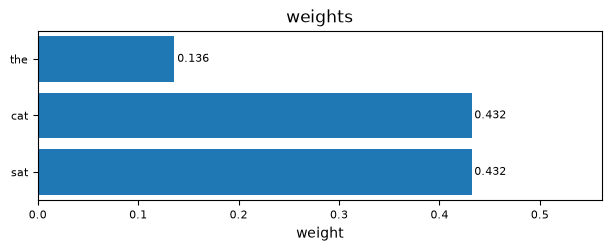

In [4]:
SCORES = [2, 4, 4]
read(SCORES)

### Solution

In [5]:
a_the, a_cat = softmax(Q[0] @ K.T / math.sqrt(D_K)), softmax(Q[1] @ K.T / math.sqrt(D_K))
display(Markdown(f"`the` gives {a_the[0]:.3f} to itself and {a_the[1]:.3f} to each of `cat` and `sat`, and reads "
                 f"({', '.join(f'{v:.3f}' for v in a_the @ V)}). `cat` gives {a_cat[1]:.3f} to itself: its scaled scores "
                 f"differ by more, so the softmax puts nearly all its weight on one word. Without the division `the` would "
                 f"give {softmax(Q[0] @ K.T)[0]:.3f} to itself."))

`the` gives 0.136 to itself and 0.432 to each of `cat` and `sat`, and reads (1.864, 6.319, 1.704). `cat` gives 0.909 to itself: its scaled scores differ by more, so the softmax puts nearly all its weight on one word. Without the division `the` would give 0.063 to itself.

## 3. The causal mask

A decoder may not read the words after the one it is at. The mask can enter
before the softmax, as a score of minus infinity, or the same cells can be
set to zero after it. Run the cell for `cat`: what does each row sum to? Then
set `WORD` to `the` and to `sat`.

masked before the softmax: 0.0010, 0.9990, 0.0000; sum 1.000
zeroed after the softmax : 0.0009, 0.9088, 0.0000; sum 0.910


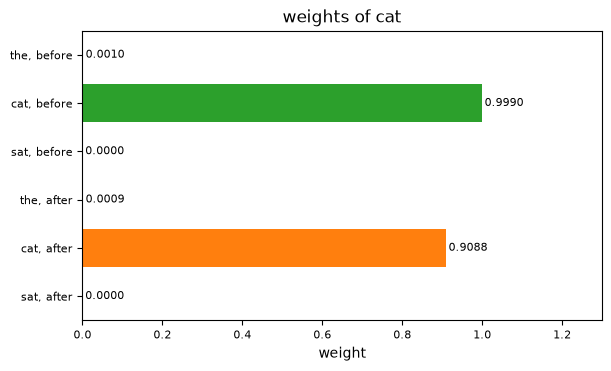

In [6]:
WORD = "cat"
show_mask(WORD)

### Solution

In [7]:
sums = "; ".join(f"`{x}` {masked(x)[0].sum():.3f} and {masked(x)[1].sum():.3f}" for x in WORDS)
display(Markdown(f"Row sums, masked before and zeroed after: {sums}. Masked before the softmax every row is a distribution; "
                 f"`the` reads only itself, with weight {masked('the')[0][0]:.0f}. Zeroed after the softmax the rows of `the` "
                 "and `cat` lose the weight their later words held, and nothing reports it; `sat` has no later word."))

Row sums, masked before and zeroed after: `the` 1.000 and 0.136; `cat` 1.000 and 0.910; `sat` 1.000 and 1.000. Masked before the softmax every row is a distribution; `the` reads only itself, with weight 1. Zeroed after the softmax the rows of `the` and `cat` lose the weight their later words held, and nothing reports it; `sat` has no later word.

## Appendix. The parameters of several heads

A layer of width d splits into h heads of width d/h. Each head has its own
query, key and value matrices of d × d/h numbers, and the output matrix W_O
mixes the heads back to width d:

3 · h · d · (d/h) + d² = 3d² + d² = 4d²,

whatever h is. The chart counts the parameters at width 512.

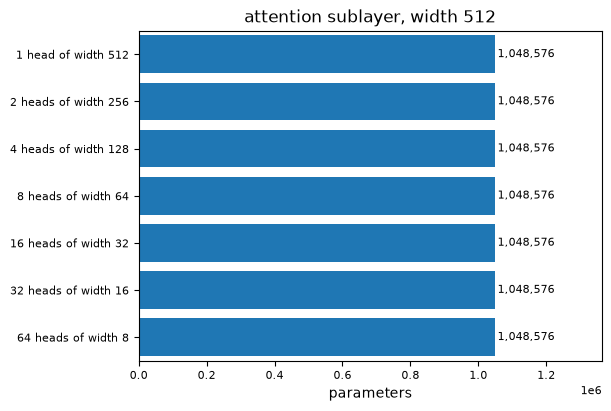

In [8]:
heads = [1, 2, 4, 8, 16, 32, 64]
bars("attention sublayer, width 512", [f"{h} head{'s' * (h > 1)} of width {512 // h}" for h in heads],
     [parameters(512, h) for h in heads], "parameters", ["C0"] * len(heads), "{:,.0f}")

**Exercise.** Set `WIDTH` and `HEADS` to GPT-2 small's, width 768 with 12
heads, then to width 768 with one head. How wide is each head, and how many
parameters does one attention sublayer hold?

In [9]:
WIDTH, HEADS = 512, 8

if not (type(WIDTH) is int and type(HEADS) is int and 1 <= HEADS <= WIDTH <= 10000 and WIDTH % HEADS == 0):
    raise Refused(f"WIDTH is {WIDTH!r} and HEADS {HEADS!r}: WIDTH takes a whole number to 10000 that HEADS divides.")
print(f"{HEADS} heads of width {WIDTH // HEADS}: {parameters(WIDTH, HEADS):,} parameters, 4 x {WIDTH}² = {4 * WIDTH ** 2:,}")

8 heads of width 64: 1,048,576 parameters, 4 x 512² = 1,048,576


### Solution

In [10]:
p = parameters(GPT2_WIDTH, GPT2_HEADS)
display(Markdown(f"GPT-2 small: {GPT2_HEADS} heads of width {GPT2_WIDTH // GPT2_HEADS}, {p:,} parameters per attention "
                 f"sublayer, and {parameters(GPT2_WIDTH, 1):,} with one head of width {GPT2_WIDTH}. Its {GPT2_LAYERS} blocks "
                 f"hold {GPT2_LAYERS * p:,} attention parameters of the model's 124,439,808."))

GPT-2 small: 12 heads of width 64, 2,359,296 parameters per attention sublayer, and 2,359,296 with one head of width 768. Its 12 blocks hold 28,311,552 attention parameters of the model's 124,439,808.